<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo II: Sesgos, justicia, y discriminación <h2></center>

Integrantes grupo:

1. Jeferson Alzate Rodriguez
2. Kamila Ignacia Salas Vargas
3. Ignacio Mariano Flores Calsina
4. Andrea Cecilia Riquelme Bugueño

# `Instrucciones Generales`


## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondas con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3

---

## `Contexto`

Los modelos de apoyo diagnóstico en salud tienen el potencial de mejorar distintos ámbitos asociados a la eficacia médica: pueden ayudar a priorizar la atención y mejorar la detección temprana de casos, pero también tienen el potencial de fallar de forma desigual entre grupos de pacientes. Un caso de esto es el algoritmo analizado por Obermeyer et al. (2019), usado en hospitales de EE.UU. para decidir qué pacientes necesitan programas de manejo de enfermedades crónicas: al usar el gasto histórico en salud como proxy de necesidad médica, el modelo subestima la gravedad de los pacientes afroamericanos, quienes históricamente reciben menos atención médica por menor acceso al sistema, no por estar más sanos.

El dataset sintético *Breast Cancer Prediction* contiene distintas variables que pueden ayudar a la detección de cáncer de mama, siendo **Cancer** la variable objetivo con la que entrenarán su modelo. La preocupación aquí es análoga: un modelo que clasifique mal, o que rinda de forma distinta entre subgrupos de pacientes, puede traducirse directamente en diagnósticos tardíos o en una falsa sensación de seguridad para algún grupo en desventaja.

`links`

- [Fuente de los datos](https://www.kaggle.com/datasets/mobeenfatimah/breast-cancer-prediction-dataset-10000-patient)
- [Link a los datos](https://drive.google.com/file/d/12E5CepN-3pv4ULE9dtd2Ty6WllUtW8pi/view?usp=drive_link)
- [Link al diccionario de datos](https://drive.google.com/file/d/1eOnjN59tlAEeeGagbSUPX-5xJnx47iUY/view?usp=sharing)
---

## Parte 1
Antes de iniciar el trabajo deben comprender los datos: de dónde provienen, qué limitaciones podrían tener, qué variables incluyen, si siguen algún estándar de calidad y cuánto hay que limpiarlos. Antes de escribir cualquier línea de código, lean y discutan esta información.

### **RESPONDER**

1. Discutan los objetivos de este dataset, los motivos detrás de su creación y las limitaciones que implica el hecho de ser sintético. Utilicen referencias para justificar su punto y expliquen para qué serviría entrenar un clasificador automático de este tipo.

    Contexto de los datos:

Este conjunto de datos representa información de 10.000 pacientes. Según Kaggle (s. f.), los datos fueron generados artificialmente y están destinados principalmente a la investigación y al aprendizaje automático.

A pesar de su origen sintético, este tipo de datos permite simular situaciones que podrían encontrarse en la realidad. Según Caballar (2025), los datos sintéticos pueden ser una solución a diferentes problemas que surgen al trabajar con datos reales, como errores en los formatos, una cantidad limitada de información en algunos sectores y la protección de la privacidad de las personas.  

Esto toma bastante sentido al trabajar con datos tan sensibles como los presentes en este conjunto de datos. No solo se incluye información relacionada con pacientes que padecen cáncer de mama, sino también datos biométricos, demográficos y otras características personales que podrían afectar la privacidad de los pacientes si correspondieran a personas reales. Por esta razón, los datos sintéticos representan una alternativa importante para reducir este tipo de riesgos y problemáticas.

Sin embargo, los datos sintéticos también presentan algunas desventajas. Los modelos utilizados para generar estos datos pueden incorporar sesgos o no representar correctamente las correlaciones existentes en la realidad. Como consecuencia, estas limitaciones pueden ser traspasadas al conjunto de datos y afectar los resultados obtenidos. En este dataset esto se observa en que el 7,2 % de los registros son hombres, cuando en la realidad solo entre el 0,5 % y el 1 % de los casos de cáncer de mama ocurre en hombres (OMS, 2024), y en que el 77 % de los hombres tiene respuesta en `Breastfeeding_History` (Taller 1).

    UTILIDAD DE UN CLASIFICADOR AUTOMÁTICO

Entrenar un clasificador automático de este tipo de datos ayudará a encontrar patrones en las características de los pacientes y realizar una clasificación relacionada con el cáncer de mama. En un contexto real, un modelo de este tipo podría utilizarse como una herramienta de apoyo para los profesionales de salud, ayudando a identificar patrones que podrían estar asociados a determinados diagnósticos o niveles de riesgo. Esto es relevante porque la detección temprana del cáncer de mama mejora considerablemente la supervivencia (OMS, 2024), y McKinney et al. (2020) mostraron que un sistema de IA usado como apoyo en el tamizaje redujo tanto los falsos positivos como los falsos negativos.

Pero el principal propósito del entrenamiento con este tipo de dataset es poder evaluar diferentes técnicas de aprendizaje automático, analizar el comportamiento de los modelos y comprender el proceso necesario para construir un sistema de clasificación. 

## Librerias y configuraciones

In [32]:
# Imports iniciales
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest, fisher_exact

# sklearn
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Aequitas
from aequitas.bias import Bias
from aequitas.fairness import Fairness
from aequitas.group import Group

# AIF360
from aif360.algorithms.postprocessing import EqOddsPostprocessing
from aif360.algorithms.preprocessing import Reweighing
from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric

# Funciones propias
import funciones_limpieza as fp

## Parte 2: Realicen el preprocesamiento de los datos y entrenen un árbol de decisión para predecir cáncer de mama a partir de la variable objetivo **Cancer**. Reporten el *accuracy* y la matriz de confusión sobre los datos de testeo.

*Puede reutilizar el jupyter o trabajar con el mismo jupyter de la entrega anterior, puede entregar una carpeta con ambos jupyter y funcioness*


### Indicaciones

- El preprocesamiento debe incluir al menos: manejo de valores faltantes, codificación de variables categóricas, normalización de variables numéricas y tratamiento de valores extremos.

- Utilicen `random_state` o semillas donde corresponda para garantizar la reproducibilidad de los resultados.

- La variable **Cancer** está desbalanceada. Investiguen el argumento `class_weight='balanced'` de sklearn para manejar este problema y aplíquenlo si lo consideran pertinente.

### **RESPONDER**

2.1 Expliquen y justifiquen los pasos del preprocesamiento.

2.2 Observando solo la matriz de confusión, ¿podemos concluir que el modelo tiene el mismo rendimiento para todos los grupos demográficos? Desarrollen y argumenten su respuesta.



## 2.1 Pre-procesamiento 

Usamos una función de un archivo que creamos llamado "funciones_limpieza", para reutilizarla en los siguientes talleres.

Funcionamiento:

### Paso 1. Eliminar columnas

Se sacan Patient_ID, Biopsy_Result y Cancer_Stage. Patient_ID, ya que es solo un número de identificación y no dice nada sobre la paciente. También se tiene que Biopsy_Result y Cancer_Stage coinciden al 100 % con Cancer (benigno siempre es 0, maligno siempre es 1). Esto se conoce como fuga de datos: se conocen después del diagnóstico, y si se dejan, el modelo "copia" la respuesta.

### Paso 2. Valores faltantes

Se eliminan 300 filas (3 %). Son las mismas 300 filas en las 5 columnas con vacíos, lo que indica que los nulos fueron generados al azar y eliminarlas no sesga los datos. Se evaluó estimar el BMI según la edad o la actividad física, pero el BMI es casi igual en todos los grupos (≈27), así que la estimación no aportaba nada. Además, la proporción de cáncer casi no cambia: pasa de 19,3 % a 19,5 %.

### Paso 3. Valores extremos

En BMI y tamaño del tumor se usa el método IQR. Los valores extremos no se borran, se recortan al límite. No se eliminaron dado que los tumores grandes pueden ser justamente la señal de cáncer. Algunos BMI (11-13) son casi imposibles en adultos, como ya lo vimos en el Taller 1, así que recortarlos reduce el efecto de datos poco creíbles.

### Paso 4. Codificación

El texto se pasa a números, porque el modelo solo entiende números. Las variables de tipo Sí/No se pasan a 1 y 0, respectivamente. Por su parte, Physical_Activity pasa a 0, 1 y 2, ya que tiene un orden (baja < moderada < alta). Mammogram_Result y Breastfeeding_History pasan a una columna 0/1 por opción, porque sus categorías no tienen un orden claro.

### Paso 5. Normalización

Finalmente, se normalizaron las variables numéricas con StandardScaler, ya que tienen escalas muy distintas: la edad va de 20 a 84 años y el ingreso de 15.000 a 150.000 dólares. Así se evita que una variable pese más solo por el tamaño de sus números. Si bien el árbol de decisión no lo requiere, se aplicó porque lo pide el enunciado y deja los datos listos para otros modelos.

Finalmente, la base de datos quedará de la siguiente manera:

In [33]:
df = fp.limpiar_datos("data/breast_cancer_prediction.csv")

df

,Age,Gender,BMI,Family_History,Smoking,Alcohol_Consumption,Physical_Activity,Hormone_Therapy,Menopause_Status,Genetic_Mutation,...,Cholesterol,Diabetes,Exercise_Days_Per_Week,Annual_Income_USD,Mammogram_Result_Abnormal,Mammogram_Result_Normal,Mammogram_Result_Suspicious,Breastfeeding_History_No,Breastfeeding_History_Not Applicable,Breastfeeding_History_Yes
0,1.008384,0,0.033731,1,1,1,2,0,1,1,...,-0.960013,0,1.515960,0.485063,0,0,1,1,0,0
1,-0.961253,1,-0.234853,0,0,0,2,0,1,0,...,0.300173,1,1.515960,-1.338910,0,1,0,0,0,1
2,1.487484,0,-1.421102,0,0,0,2,0,0,0,...,1.235150,0,-1.112403,-1.216208,0,0,1,0,0,1
3,-0.641852,0,-0.055797,1,1,0,1,0,1,0,...,-0.695780,0,1.515960,-0.366660,0,1,0,0,0,1
4,-0.482152,0,0.347080,1,1,0,1,0,1,0,...,1.052220,0,-1.550463,0.219064,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1.700418,0,0.973777,0,0,1,2,0,1,1,...,-0.980339,0,0.639839,-0.910222,0,1,0,0,1,0
9996,-0.482152,0,-0.525820,0,1,0,1,1,0,0,...,-0.919362,0,1.515960,0.727882,1,0,0,1,0,0
9997,-1.546820,0,-0.190089,1,0,1,1,0,0,0,...,-0.004711,0,1.077900,1.120778,0,1,0,1,0,0
9998,-0.428919,0,-1.174900,0,0,0,1,0,1,1,...,-0.797408,0,0.201779,0.189437,1,0,0,0,1,0


    Árbol de decisión

Antes de empezar a realizar el árbol de decisión, analizaremos más a profundidad la variable `Cancer`, esto es muy importante dado que si esta variable está desbalanceada, nuestros procedimientos de predicción pueden verse sesgados, porque el algoritmo aprenderá a predecir siempre la clase mayoritaria e ignorando la minoritaria.

Para ver esto, contaremos los valores de nuestra variable categórica `Cancer`.

In [34]:
df["Cancer"].value_counts(normalize=True)

Cancer
0    0.805464
1    0.194536
Name: proportion, dtype: float64

Podemos notar que la variable Cancer presenta una distribución desbalanceada, ya que la clase 1 representa una proporción de aproximadamente un 19 % de las observaciones, mientras que la clase 0 representa el porcentaje restante.

Para abordar este problema, la librería Scikit-learn proporciona el argumento class_weight, el cual permite asignar diferentes pesos a las clases durante el entrenamiento de un modelo. En particular y según GeeksforGeeks. (2025, 23 julio), la opción class_weight="balanced" resulta útil cuando se trabaja con conjuntos de datos desbalanceados, como en nuestro caso. Esta opción asigna automáticamente un mayor peso a la clase minoritaria y un menor peso a la clase mayoritaria, haciendo que los errores cometidos sobre la clase minoritaria tengan una mayor influencia durante el entrenamiento del modelo.

El cálculo de estos pesos se realiza mediante la siguiente fórmula:

$$
w_j = \frac{n_{\text{samples}}}{n_{\text{classes}} \times n_j}
$$

Donde:

$n_{\text{samples}}$: número total de muestras del conjunto de datos.

$n_{\text{classes}}$: número de clases diferentes.

$n_j$: número de muestras pertenecientes a la clase $j$.

Por lo tanto, mientras menor sea la cantidad de observaciones de una clase, mayor será el peso asignado a esta.

El parámetro class_weight acepta diferentes valores:

``None`` (predeterminado): no se asignan pesos especiales a las clases, por lo que todas tienen el mismo peso.

``balanced``: los pesos se calculan automáticamente de forma inversamente proporcional a la frecuencia de cada clase.

``Diccionario``: permite establecer manualmente un peso para cada clase. Las claves corresponden a las etiquetas de las clases y los valores corresponden a sus respectivos pesos.

Teniendo en cuenta lo anterior, realizaremos el árbol de decisión con esta corrección.

In [35]:
# Definimos nuestras variables
X = df.drop("Cancer", axis=1)
y = df["Cancer"]  # Variable objetivo

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,  # 80% Entrenamiento - 20% Prueba
    random_state=42,
    stratify=y
)

# Creación del árbol
modelo = DecisionTreeClassifier(
    class_weight="balanced",  # Utilizamos este parametro
    random_state=42
)

# Lo entrenamos
modelo.fit(X_train, y_train)

# Hacemos las predicciones, esta variable contiene la predicción del árbol
# para los pacientes que se dejaron afuera del entrenamiento
y_pred = modelo.predict(X_test)

Ya con el árbol creado probaremos su accuracy:

In [36]:
accuracy = accuracy_score(y_test, y_pred)
accuracy

0.9907216494845361

## 2.2 ¿Podemos concluir que el modelo tiene el mismo rendimiento para todos los grupos demográficos?

[[1558    5]
 [  13  364]]


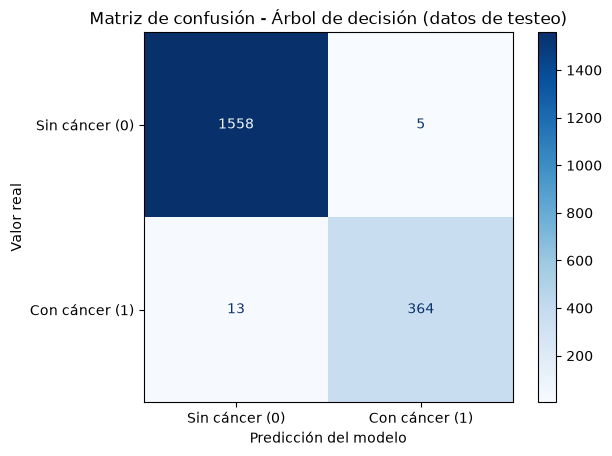

In [37]:
# Matriz de confusión

# Calculamos la matriz sobre datos de testeo
matriz = confusion_matrix(y_test, y_pred)
print(matriz)

# La graficamos para que sea más fácil de interpretar
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Sin cáncer (0)", "Con cáncer (1)"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Árbol de decisión (datos de testeo)")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.show()

- Arriba a la izquierda (VN): pacientes sanas bien clasificadas.
- Arriba a la derecha (FP): pacientes sanas que el modelo marcó con cáncer.
- Abajo a la izquierda (FN): pacientes con cáncer que el modelo no detectó.
- Abajo a la derecha (VP): pacientes con cáncer bien detectadas.

La matriz de confusión no permite concluir que el modelo tenga el mismo rendimiento en todos los grupos demográficos, ya que es una medida agregada: resume los aciertos y errores del modelo sobre el total del conjunto de prueba, sin distinguir a qué grupo pertenece cada paciente.

Sobre los 1.940 pacientes del conjunto de prueba, el modelo clasificó correctamente 1.558 casos sin cáncer (verdaderos negativos) y 364 casos con cáncer (verdaderos positivos). Cometió 5 falsos positivos y 13 falsos negativos, lo que equivale a un accuracy de 99,07 %, una tasa de falsos negativos de aproximadamente 3,4 % y una tasa de falsos positivos de 0,3 %. A nivel global, estos resultados sugieren un modelo con muy buen desempeño.

Sin embargo, la matriz no indica en qué pacientes se concentran esos errores. En un contexto de apoyo diagnóstico, los 13 falsos negativos son los errores más graves, pues corresponden a pacientes con cáncer a quienes el modelo les indicaría que no lo tienen, lo que puede traducirse en diagnósticos tardíos o en una falsa sensación de seguridad. La matriz global no permite saber si esos 13 casos se distribuyen de forma similar entre grupos de edad, niveles de ingreso, BMI o género, o si se concentran en uno de ellos. Ambos escenarios producen exactamente la misma matriz de confusión, pero tienen implicancias éticas muy distintas.

Este problema se acentúa cuando existen grupos minoritarios en los datos. Por ejemplo, en el conjunto de prueba solo 171 pacientes son hombres (8,8 %). Si el modelo tuviera un desempeño considerablemente peor en este grupo, sus errores tendrían un peso pequeño en el total y apenas afectarían la matriz global o el accuracy. A esto se le conoce como sesgo de agregación: un modelo evaluado sobre la población completa puede parecer adecuado y, aun así, rendir peor en subgrupos específicos (Suresh & Guttag, 2021).

Un caso que ilustra este riesgo es el algoritmo analizado por Obermeyer et al. (2019). Al comparar pacientes con el mismo puntaje de riesgo, los pacientes afroamericanos estaban en promedio más enfermos que los blancos, un sesgo que solo se hizo visible al desagregar los resultados por raza y no a partir de las métricas globales.

Por lo tanto, un accuracy alto y una matriz de confusión favorable no son evidencia suficiente de equidad. Para evaluar si el modelo rinde igual en todos los grupos, es necesario desagregar las métricas por atributo sensible y comparar, por ejemplo, las tasas de falsos negativos entre grupos. Como se mostrará en la Parte 3, esto ocurre en nuestros datos: con el mismo modelo y la misma matriz global, la tasa de falsos negativos es de 9,8 % en pacientes jóvenes frente a 2,2 % en adultas.


## Parte 3: Evalúen las predicciones del modelo mediante las métricas de *fairness* de Aequitas.

### **Indicaciones**

Consideren como posibles atributos demográficos sensibles del dataset: `age`, `Gender`, `BMI` y `Annual_Income_USD`.

**Paso 1: Categoricen las variables continuas.**
Aequitas requiere variables categóricas. Para atributos continuos o con muchas categorías, como `age`, creen una columna auxiliar que agrupe los valores en tramos. Por ejemplo:

- 0-30 años: joven
- 30-40 años: adulto
- 40-60 años: adulto mayor

**Paso 2: Elijan al menos 2 atributos sensibles y definan sus grupos.**
De los cuatro atributos mencionados, escojan al menos dos para el análisis. Para cada uno, definan sus categorías (agrupándolas si es necesario, como en el paso 1).

**Paso 3: Definan, dentro de cada atributo, qué grupo es privilegiado y cuál no privilegiado.**
El grupo privilegiado es aquel que ustedes consideran de referencia, es decir, contra el cual se comparará el desempeño del modelo en los demás grupos del mismo atributo. Por ejemplo, para `age` podrían definir:

| Grupo | Categoría |
|---|---|
| Privilegiado | adulto |
| No privilegiado | joven |
| No privilegiado | adulto mayor |

Y para `Annual_Income_USD`, tras agruparlo en tramos (por ejemplo, ingreso alto / ingreso bajo):

| Grupo | Categoría |
|---|---|
| Privilegiado | ingreso alto |
| No privilegiado | ingreso bajo |

La elección de qué categoría es privilegiada y cuál no queda a su criterio, pero deben justificarla.

**Paso 4: Reporten las métricas.**
Finalmente, reporten las métricas de *False Negative Rate Parity* y *False Discovery Rate Parity* para los atributos y grupos definidos.

### **RESPONDER**

Pregunta 3.1 Expliquen los resultados obtenidos.

Pregunta 3.2 ¿Cuán justas se pueden considerar las predicciones del modelo para cada grupo? ¿Cómo relacionarían esto con los contenidos del curso?

Pregunta 3.3 El dataset no contiene variables asociadas a la raza, por ejemplo. ¿Significa esto que el modelo no aprenderá sesgos respecto a ese grupo? Investiguen y justifiquen su respuesta.

In [38]:
# Recuperar valores originales
df_original = pd.read_csv("data/breast_cancer_prediction.csv")
df_test = df_original.loc[
    X_test.index, ["Age", "Gender", "BMI", "Annual_Income_USD"]
].copy()

df_test["score"] = y_pred
df_test["label_value"] = y_test.values

In [39]:
# Grupos de edad (el rango del dataset va de 20 a 84 años)
df_test["grupo_edad"] = pd.cut(
    df_test["Age"],
    bins=[0, 40, 60, 100],
    labels=["joven", "adulto", "adulto mayor"],
    right=False  # [0,40): joven, [40,60): adulto, [60,100): adulto mayor
)

# Grupos de ingreso (el rango va de ~15.000 a ~150.000 USD)
df_test["grupo_ingreso"] = pd.cut(
    df_test["Annual_Income_USD"],
    bins=[0, 50000, 100000, float("inf")],
    labels=["ingreso bajo", "ingreso medio", "ingreso alto"],
    right=False
)

# Aequitas necesita que los atributos sean texto
df_aeq = df_test[["score", "label_value", "grupo_edad", "grupo_ingreso"]]
df_aeq = df_aeq.astype({"grupo_edad": str, "grupo_ingreso": str})

df_aeq["grupo_edad"].value_counts(), df_aeq["grupo_ingreso"].value_counts()

(grupo_edad
 adulto mayor    775
 joven           593
 adulto          572
 Name: count, dtype: int64,
 grupo_ingreso
 ingreso alto     719
 ingreso medio    695
 ingreso bajo     526
 Name: count, dtype: int64)

In [40]:
g = Group()
xtab, _ = g.get_crosstabs(df_aeq)

xtab[["attribute_name", "attribute_value", "group_size",
      "tp", "fn", "fp", "fnr", "fdr"]]

,attribute_name,attribute_value,group_size,tp,fn,fp,fnr,fdr
0,grupo_edad,adulto,572,89,2,2,0.021978,0.021978
1,grupo_edad,adulto mayor,775,229,6,0,0.025532,0.000000
2,grupo_edad,joven,593,46,5,3,0.098039,0.061224
3,grupo_ingreso,ingreso alto,719,151,4,2,0.025806,0.013072
4,grupo_ingreso,ingreso bajo,526,90,3,1,0.032258,0.010989
5,grupo_ingreso,ingreso medio,695,123,6,2,0.046512,0.016000


In [41]:
b = Bias()
bdf = b.get_disparity_predefined_groups(
    xtab,
    original_df=df_aeq,
    ref_groups_dict={"grupo_edad": "adulto",
                     "grupo_ingreso": "ingreso alto"},
    alpha=0.05,
    mask_significance=True
)

In [42]:
f = Fairness()
fdf = f.get_group_value_fairness(bdf)

fdf[["attribute_name", "attribute_value",
     "fnr", "fnr_disparity", "FNR Parity",
     "fdr", "fdr_disparity", "FDR Parity"]]

,attribute_name,attribute_value,fnr,fnr_disparity,FNR Parity,fdr,fdr_disparity,FDR Parity
0,grupo_edad,adulto,0.021978,1.000000,True,0.021978,1.000000,True
1,grupo_edad,adulto mayor,0.025532,1.161702,True,0.000000,0.000000,False
2,grupo_edad,joven,0.098039,4.460784,False,0.061224,2.785714,False
3,grupo_ingreso,ingreso alto,0.025806,1.000000,True,0.013072,1.000000,True
4,grupo_ingreso,ingreso bajo,0.032258,1.250000,True,0.010989,0.840659,True
5,grupo_ingreso,ingreso medio,0.046512,1.802326,False,0.016000,1.224000,True


In [43]:
# Intervalo de confianza para la FNR de cada grupo
ics = [binomtest(int(f), int(f + t)).proportion_ci(method="wilson")
       for f, t in zip(xtab["fn"], xtab["tp"])]

tabla_ic = xtab[["attribute_name", "attribute_value", "tp", "fn"]].copy()
tabla_ic["positivos"] = tabla_ic["tp"] + tabla_ic["fn"]
tabla_ic["fnr_ic_inf"] = [c.low for c in ics]
tabla_ic["fnr_ic_sup"] = [c.high for c in ics]
display(tabla_ic)

# Test exacto de Fisher: ¿la diferencia de FNR es estadísticamente
# significativa?
x = xtab.set_index("attribute_value")


def fisher_fnr(g1, g2):
    """Retorna el p-valor del test de Fisher para la FNR de dos grupos."""
    a, b = x.loc[g1], x.loc[g2]
    return fisher_exact([[a["fn"], a["tp"]], [b["fn"], b["tp"]]])[1]


print("p-valor joven vs adulto:", fisher_fnr("joven", "adulto"))
print("p-valor ingreso medio vs alto:",
      fisher_fnr("ingreso medio", "ingreso alto"))

,attribute_name,attribute_value,tp,fn,positivos,fnr_ic_inf,fnr_ic_sup
0,grupo_edad,adulto,89,2,91,0.006048,0.076632
1,grupo_edad,adulto mayor,229,6,235,0.011753,0.054573
2,grupo_edad,joven,46,5,51,0.042608,0.209782
3,grupo_ingreso,ingreso alto,151,4,155,0.010080,0.064469
4,grupo_ingreso,ingreso bajo,90,3,93,0.011031,0.090594
5,grupo_ingreso,ingreso medio,123,6,129,0.021489,0.097762


p-valor joven vs adulto: 0.09794079345781659
p-valor ingreso medio vs alto: 0.5201670127602769


## 3.1

Se analizaron dos atributos sensibles. La edad (rango del dataset: 20 a 84 años) se agrupó en joven (20–39 años), adulta (40–59 años) y adulta mayor (60 años o más). El ingreso anual se agrupó en bajo (menos de 50.000 USD), medio (50.000 a 99.999 USD) y alto (100.000 USD o más). Como grupos de referencia se definió a las pacientes adultas, por ser la población objetivo de los programas de tamizaje mamográfico (US Preventive Services Task Force, 2024), y a las de ingreso alto, por tener, en general, mayor acceso a la salud (Braveman & Gottlieb, 2014). Se reportan la tasa de falsos negativos (FNR), es decir, la proporción de pacientes con cáncer que el modelo no detecta, y la tasa de falsos descubrimientos (FDR), es decir, la proporción de alertas de cáncer que resultan erróneas. Siguiendo a Saleiro et al. (2018), Aequitas considera que hay paridad cuando la disparidad frente al grupo de referencia está entre 0,8 y 1,25.
 
| Atributo | Grupo | FNR (disparidad) | Paridad FNR | FDR (disparidad) | Paridad FDR |
|---|---|---|---|---|---|
| Edad | adulta (referencia) | 2,2 % (1,00) | Sí | 2,2 % (1,00) | Sí |
| Edad | joven | 9,8 % (4,46) | **No** | 6,1 % (2,79) | **No** |
| Edad | adulta mayor | 2,6 % (1,16) | Sí | 0,0 % (0,00) | No* |
| Ingreso | alto (referencia) | 2,6 % (1,00) | Sí | 1,3 % (1,00) | Sí |
| Ingreso | bajo | 3,2 % (1,25) | Sí (en el límite) | 1,1 % (0,84) | Sí |
| Ingreso | medio | 4,7 % (1,80) | **No** | 1,6 % (1,22) | Sí |
 
\*Aequitas marca "sin paridad" porque la disparidad queda bajo 0,8, pero un FDR de 0 % significa que el modelo no emitió ninguna falsa alarma en ese grupo, por lo que no constituye un perjuicio.
 
En edad se observa la mayor disparidad. Las pacientes jóvenes tienen una FNR de 9,8 %, frente a 2,2 % en las adultas: el modelo no detecta a una de cada diez jóvenes con cáncer. Además, su FDR también es mayor (6,1 % frente a 2,2 %), por lo que el modelo se equivoca más en las jóvenes en ambas direcciones. Las adultas mayores alcanzan paridad en FNR (1,16). En ingreso, solo el grupo de ingreso medio queda fuera del rango de paridad en FNR (4,7 % frente a 2,6 % del ingreso alto, disparidad de 1,80); el ingreso bajo queda justo en el límite (1,25) y no se observa un patrón monótono, ya que el grupo bajo tiene una FNR menor que el medio.
 
Una posible explicación para el caso de las jóvenes es la diferencia de prevalencia: solo el 8,6 % de las jóvenes tiene cáncer, frente al 15,9 % de las adultas y al 30,3 % de las adultas mayores. Al contar con menos casos positivos, el modelo aprende peor los patrones de este grupo, lo que corresponde a un sesgo de representación.
 
Estos resultados deben interpretarse con cautela. La FNR de las jóvenes se basa en solo 5 falsos negativos sobre 51 casos positivos: su intervalo de confianza al 95 % va de 4,3 % a 21,0 %, y se solapa con el de las adultas (0,6 % a 7,7 %). Además, la diferencia no es estadísticamente significativa al 5 % (test exacto de Fisher, p ≈ 0,10). En ingreso, la diferencia entre el grupo medio y el alto tampoco lo es (p ≈ 0,52). Es decir, los indicios de disparidad, sobre todo en edad, son marcados, pero el tamaño de la muestra no permite confirmarlos con certeza.

## 3.2

Las predicciones no son igualmente justas para todos los grupos, a pesar del accuracy global de 99 %. Esto confirma lo planteado en la pregunta 2.2: una métrica agregada puede ocultar diferencias entre subgrupos. Por grupo: las pacientes jóvenes son las menos favorecidas, con más falsos negativos y más falsas alarmas; las adultas y las adultas mayores reciben un trato comparable en FNR, y estas últimas no tuvieron falsas alarmas; en ingreso, el grupo alto y el bajo son equivalentes según Aequitas, mientras que el medio queda fuera de paridad en FNR.
 
El caso más preocupante es el de las pacientes jóvenes. En un contexto médico, la FNR es la métrica más relevante, porque un falso negativo implica que una paciente con cáncer recibe un resultado tranquilizador y puede retrasar su tratamiento. Que este error sea unas 4,5 veces más frecuente en las jóvenes implica que los costos de las fallas del modelo no se distribuyen de forma equitativa. Además, como las menores de 40 años no suelen estar incluidas en los programas de tamizaje, tienen menos oportunidades de que otro examen corrija el error. En ingreso, en cambio, no hay un patrón claro (el grupo bajo tiene menor FNR que el medio), por lo que no podemos afirmar que el modelo perjudique sistemáticamente a los grupos con menor acceso a la salud, como ocurría en el caso de Obermeyer et al. (2019).
 
En relación con el curso, exigir paridad en FNR corresponde al criterio de igualdad de oportunidades (Hardt et al., 2016): todas las pacientes con cáncer deberían tener la misma probabilidad de ser detectadas. Exigir paridad en FDR corresponde a la paridad predictiva: una alerta de cáncer debería ser igual de confiable en todos los grupos. Cuando la prevalencia difiere entre grupos, como en nuestros datos (8,6 %, 15,9 % y 30,3 % según edad), no es posible satisfacer a la vez la igualdad de oportunidades ampliada (FNR y FPR iguales) y la paridad predictiva (Chouldechova, 2017; Kleinberg et al., 2016). Por lo tanto, definir qué es "justo" es una decisión ética y no solo técnica. En este contexto, consideramos prioritario reducir la disparidad en FNR, ya que un cáncer no detectado es mucho más grave que una alerta falsa, cuyo costo es principalmente una evaluación adicional.

## 3.3

No. Excluir una variable sensible no garantiza que el modelo esté libre de sesgos respecto a ese grupo. Este enfoque, conocido como fairness through unawareness (Kusner et al., 2017), es insuficiente por tres razones.

Primero, las variables proxy: Otras variables pueden estar correlacionadas con la raza y transmitir esa información de forma indirecta, lo que Dwork et al. (2012) describen como codificaciones redundantes; Barocas y Selbst (2016) muestran además cómo los modelos entrenados con datos históricos pueden reproducir discriminación sin usar atributos protegidos. Por ejemplo, `Annual_Income_USD` podría actuar como proxy de la raza en contextos con brechas raciales de ingreso. El caso de Obermeyer et al. (2019) lo ilustra: el algoritmo no usaba la raza, pero al emplear el gasto en salud como proxy de necesidad médica terminó subestimando la gravedad de los pacientes afroamericanos.
 
Segundo, el sesgo en la generación de los datos: Si los datos, o los modelos usados para generar este conjunto sintético, representan mayoritariamente a un grupo racial, el modelo aprenderá sus patrones y podría rendir peor en otros. Esto corresponde a un sesgo de representación, el mismo mecanismo observado en la pregunta 3.1 con las pacientes jóvenes.
 
Tercero, sin la variable no es posible auditar el sesgo: No se pueden calcular métricas como FNR o FDR por raza, como sí se hizo con la edad y el ingreso. En conclusión, eliminar la variable no elimina el sesgo, solo lo vuelve invisible.

## Parte 4: Aplique el algoritmo EqOddsPostProcessing sobre las predicciones del modelo de la pregunta 1. Obtenga las predicciones modificadas y evalúelas.

#### Indicaciones:

- Obtenga tanto las instancias de BinaryLabelDatasetMetric como de ClassificationMetric y calcule al menos una métrica de Fairness.

### **RESPONDER**

pregunta 4.1: comentar brevemente los resultados obtenidos, y evaluar los cambios en las métricas de Fairness. Reflexionar sobre los beneficios y limitaciones


In [44]:
df_test["edad_binaria"] = df_test["grupo_edad"].map({
    "joven": 0,
    "adulto": 1,
    "adulto mayor": 0
})
df_test[["grupo_edad", "edad_binaria"]].value_counts()

grupo_edad    edad_binaria
adulto mayor  0               775
joven         0               593
adulto        1               572
Name: count, dtype: int64

In [45]:
df_test["ingreso_binario"] = df_test["grupo_ingreso"].map({
    "ingreso bajo": 0,
    "ingreso medio": 0,
    "ingreso alto": 1
})
df_test[["grupo_ingreso", "ingreso_binario"]].value_counts()

grupo_ingreso  ingreso_binario
ingreso alto   1                  719
ingreso medio  0                  695
ingreso bajo   0                  526
Name: count, dtype: int64

In [46]:
df_aif_pred = X_test.copy()
df_aif_pred["edad_binaria"] = df_test["edad_binaria"]
df_aif_pred["ingreso_binario"] = df_test["ingreso_binario"]
df_aif_pred["Cancer"] = y_pred

df_aif_real = X_test.copy()
df_aif_real["edad_binaria"] = df_test["edad_binaria"]
df_aif_real["ingreso_binario"] = df_test["ingreso_binario"]
df_aif_real["Cancer"] = y_test.values

print(df_aif_pred.shape, df_aif_real.shape)

(1940, 26) (1940, 26)


In [47]:
def get_aif_metrics(attr, df, label_names):
    """Crea un BinaryLabelDataset y su BinaryLabelDatasetMetric."""
    privileged_groups = [{attr: 1}]
    unprivileged_groups = [{attr: 0}]

    atributos_params = dict(protected_attribute_names=[attr],
                            label_names=label_names)
    dt = BinaryLabelDataset(
        df=df, **atributos_params, favorable_label=1, unfavorable_label=0
    )

    metrica = BinaryLabelDatasetMetric(
        dt,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups
    )
    return metrica, dt

In [48]:
metrica_edad, dt_edad = get_aif_metrics("edad_binaria", df_aif_real,
                                        ["Cancer"])
print("Prevalencia privilegiado (adultas):",
      metrica_edad.base_rate(privileged=True))
print("Prevalencia no privilegiado (jóvenes + adultas mayores):",
      metrica_edad.base_rate(privileged=False))

Prevalencia privilegiado (adultas): 0.1590909090909091
Prevalencia no privilegiado (jóvenes + adultas mayores): 0.20906432748538012


In [49]:
def aplicar_EqOddsPostProcessing(group, df_test_pred, df_test):
    """Aplica EqOddsPostprocessing e imprime las métricas antes/después."""
    privileged_groups = [{group: 1}]
    unprivileged_groups = [{group: 0}]

    _, test_pred_aifdf = get_aif_metrics(group, df_test_pred, ["Cancer"])
    _, test_aifdf = get_aif_metrics(group, df_test, ["Cancer"])

    cm_antes = ClassificationMetric(
        test_aifdf,
        test_pred_aifdf,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups,
    )

    roc = EqOddsPostprocessing(
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups,
        seed=103,
    )
    roc.fit(test_aifdf, test_pred_aifdf)
    corrected_pred = roc.predict(test_pred_aifdf)

    cm = ClassificationMetric(
        test_aifdf,
        corrected_pred,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups,
    )
    for nombre, i in [("Antes de EqOdds", cm_antes),
                      ("Después de EqOdds", cm)]:
        print(f"--- {nombre} ---")
        print(f"  Equal opportunity difference : "
              f"{i.equal_opportunity_difference():.4f}")
        print(f"  FNR grupo privilegiado       : "
              f"{i.false_negative_rate(privileged=True):.4f}")
        print(f"  FNR grupo no privilegiado    : "
              f"{i.false_negative_rate(privileged=False):.4f}")
        print(f"  FNR ratio (no-priv / priv)   : "
              f"{i.false_negative_rate_ratio():.4f}")
        print(f"  FPR grupo privilegiado       : "
              f"{i.false_positive_rate(privileged=True):.4f}")
        print(f"  FPR grupo no privilegiado    : "
              f"{i.false_positive_rate(privileged=False):.4f}")
        print(f"  FPR ratio (no-priv / priv)   : "
              f"{i.false_positive_rate_ratio():.4f}")

    bldm_antes = BinaryLabelDatasetMetric(
        test_pred_aifdf,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups
    )
    bldm_despues = BinaryLabelDatasetMetric(
        corrected_pred,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups
    )
    for nombre, b, c in [("Antes", bldm_antes, cm_antes),
                         ("Después", bldm_despues, cm)]:
        print(f"--- {nombre} ---")
        print(f"  Statistical parity difference: "
              f"{b.statistical_parity_difference():.4f}")
        print(f"  Disparate impact             : "
              f"{b.disparate_impact():.4f}")
        print(f"  Accuracy global              : {c.accuracy():.4f}")

In [50]:
print("=== Edad (adultas = privilegiado) ===")
aplicar_EqOddsPostProcessing("edad_binaria", df_aif_pred, df_aif_real)

=== Edad (adultas = privilegiado) ===
--- Antes de EqOdds ---
  Equal opportunity difference : -0.0165
  FNR grupo privilegiado       : 0.0220
  FNR grupo no privilegiado    : 0.0385
  FNR ratio (no-priv / priv)   : 1.7500
  FPR grupo privilegiado       : 0.0042
  FPR grupo no privilegiado    : 0.0028
  FPR ratio (no-priv / priv)   : 0.6668
--- Después de EqOdds ---
  Equal opportunity difference : -0.0055
  FNR grupo privilegiado       : 0.0330
  FNR grupo no privilegiado    : 0.0385
  FNR ratio (no-priv / priv)   : 1.1667
  FPR grupo privilegiado       : 0.0042
  FPR grupo no privilegiado    : 0.0037
  FPR ratio (no-priv / priv)   : 0.8891
--- Antes ---
  Statistical parity difference: 0.0441
  Disparate impact             : 1.2774
  Accuracy global              : 0.9907
--- Después ---
  Statistical parity difference: 0.0466
  Disparate impact             : 1.2962
  Accuracy global              : 0.9897


In [51]:
print("=== Ingreso (ingreso alto = privilegiado) ===")
aplicar_EqOddsPostProcessing("ingreso_binario", df_aif_pred, df_aif_real)

=== Ingreso (ingreso alto = privilegiado) ===
--- Antes de EqOdds ---
  Equal opportunity difference : -0.0147
  FNR grupo privilegiado       : 0.0258
  FNR grupo no privilegiado    : 0.0405
  FNR ratio (no-priv / priv)   : 1.5709
  FPR grupo privilegiado       : 0.0035
  FPR grupo no privilegiado    : 0.0030
  FPR ratio (no-priv / priv)   : 0.8468
--- Después de EqOdds ---
  Equal opportunity difference : -0.0018
  FNR grupo privilegiado       : 0.0387
  FNR grupo no privilegiado    : 0.0405
  FNR ratio (no-priv / priv)   : 1.0473
  FPR grupo privilegiado       : 0.0035
  FPR grupo no privilegiado    : 0.0030
  FPR ratio (no-priv / priv)   : 0.8468
--- Antes ---
  Statistical parity difference: -0.0359
  Disparate impact             : 0.8313
  Accuracy global              : 0.9907
--- Después ---
  Statistical parity difference: -0.0331
  Disparate impact             : 0.8423
  Accuracy global              : 0.9897



### 4.1
Se aplicó EqOdds (The AI Fairness 360 Authors, 2024) con la edad, usando a las adultas como grupo privilegiado, y con el ingreso, usando el ingreso alto como grupo privilegiado. Podemos ver que en edad, después de aplicar EqOdds, la tasa de falsos negativos del grupo privilegiado aumentó, lo que nos da a entender que hay pacientes que tienen cáncer pero no fueron detectadas, lo cual es un error grave en este contexto; en cambio, la FNR del grupo no privilegiado se mantuvo. A causa de esto, el FNR ratio pasó de 1,75 a 1,17, lo cual nos indica que los grupos quedaron más parecidos.
Por otro lado, en la tasa de falsos positivos, la del grupo privilegiado se mantuvo, mientras que la del grupo no privilegiado aumentó, y el FPR ratio aumentó, lo que nos dice que las falsas alarmas quedaron mejor repartidas entre estos dos grupos.

En el caso del ingreso, la FNR del grupo privilegiado aumentó y la del grupo no privilegiado se mantuvo igual, lo que implica que el FNR ratio bajó, dándonos la misma explicación que con la edad.
En cuanto a la FPR, se mantuvo igual en ambos grupos, es decir, no cambió ningún falso positivo, ya que el FPR ratio se encontraba dentro del rango de paridad desde antes de aplicar el algoritmo.

Las métricas de BinaryLabelDatasetMetric casi no cambiaron (Statistical parity difference de 0,044 a 0,047 en edad y de −0,036 a −0,033 en ingreso), lo cual es esperable porque EqOdds iguala tasas de error y no la proporción de predicciones positivas. El accuracy bajó levemente de 99,07 % a 98,97 %.

Uno de los beneficios de EqOdds es que no requiere reentrenar el modelo. Además, uno de sus objetivos es que las tasas de error sean similares entre los grupos, lo cual se cumple al ver nuestros resultados. Otro de sus beneficios es que es fácil de aplicar y de entender los resultados que entrega.
Una de sus limitaciones es que cambia los diagnósticos al azar y no por la información que se tiene de los pacientes, ya que podría haber dos pacientes con la misma información médica que reciban distintos resultados del modelo. También, los cambios fueron de pocos pacientes, a lo más 1 o 2, y eso conllevó a que los ratios cambiaran, por lo que esos resultados son frágiles.
Además, actúa sobre las predicciones, no sobre los datos ni el modelo: si es que el sesgo viene de la representación, como la baja prevalencia en jóvenes, el método no logra eliminar la causa, sino que solo redistribuye los errores entre grupos, sin que el modelo pueda aprender a detectar el cáncer en el grupo no privilegiado.
Otra limitación es que, al juntar a las jóvenes con las adultas mayores en un solo grupo, la FNR de las jóvenes (9,8 %) queda diluida en 3,8 %, por lo que el algoritmo no corrige directamente al grupo más afectado. Además, EqOdds se ajustó y evaluó sobre el mismo conjunto de prueba, por lo que la mejora puede ser optimista.
Y una de las más importantes es que el modelo logró la equidad empeorando al grupo privilegiado en lugar de mejorar al desfavorecido; esto, en el contexto de detección de cáncer, es un error gravísimo, ya que se perdería un diagnóstico.


## **Parte 5** (bonus +5 decimas) :  

Aplique el algoritmo de Reweighing sobre los datos de entrenamiento. Compare las métricas de Fairness para los datos de entrenamiento antes y después de aplicar Reweighing.

Luego, entrene un Arbol de decisión utilizando los datos de entrenamiento modificados y obtenga las métricas de Fairness de las predicciones de dicho modelo.

Analice cómo varió el *accuracy* del modelo respecto al original y las métricas de Fairness y reflexione sobre las implicancias sociales de estas decisiones.

### Indicaciones:
Puedes considerar los grupos priviligiados/no priviligiados mencionados en la parte 3. Considere al menos 2.

In [52]:
df_train_grupos = df_original.loc[
    X_train.index, ["Age", "Annual_Income_USD"]
].copy()
df_train_grupos["edad_binaria"] = (
    (df_train_grupos["Age"] >= 40) & (df_train_grupos["Age"] < 60)
).astype(int)
df_train_grupos["ingreso_binario"] = (
    df_train_grupos["Annual_Income_USD"] >= 100000
).astype(int)
print(df_train_grupos["edad_binaria"].value_counts())
print(df_train_grupos["ingreso_binario"].value_counts())

edad_binaria
0    5367
1    2393
Name: count, dtype: int64
ingreso_binario
0    4900
1    2860
Name: count, dtype: int64


In [53]:
df_train = X_train.copy()
df_train["edad_binaria"] = df_train_grupos["edad_binaria"]
df_train["ingreso_binario"] = df_train_grupos["ingreso_binario"]
df_train["Cancer"] = y_train.values
print(df_train.shape)

(7760, 26)


In [54]:
metrica_train_edad, _ = get_aif_metrics("edad_binaria", df_train, ["Cancer"])
print("SPD edad ANTES:", metrica_train_edad.mean_difference())

SPD edad ANTES: 0.029393693845419427


In [55]:
metrica_train_ingresos, _ = get_aif_metrics("ingreso_binario", df_train,
                                            ["Cancer"])
print("SPD ingresos ANTES:", metrica_train_ingresos.mean_difference())

SPD ingresos ANTES: -0.008571428571428591


In [56]:
def aplicar_reweighing(group, df_train):
    """Aplica Reweighing y retorna el dataset con los nuevos pesos."""
    privileged_groups = [{group: 1}]
    unprivileged_groups = [{group: 0}]

    atributos_params = dict(protected_attribute_names=[group],
                            label_names=["Cancer"])
    dt_train = BinaryLabelDataset(df=df_train, **atributos_params)

    reweight = Reweighing(unprivileged_groups=unprivileged_groups,
                          privileged_groups=privileged_groups)
    reweight = reweight.fit_transform(dt_train)
    return reweight


def obtener_metricas_reweighing(reweighted, group):
    """Imprime la Statistical Parity Difference del dataset reponderado."""
    privileged_groups = [{group: 1}]
    unprivileged_groups = [{group: 0}]
    reweighted_metrics = BinaryLabelDatasetMetric(
        reweighted,
        unprivileged_groups=unprivileged_groups,
        privileged_groups=privileged_groups
    )
    spd = reweighted_metrics.mean_difference()
    print(f" Statistical Parity Difference({group}): {spd:.4f}")

In [57]:
print(" Reweighing: efecto sobre Statistical Parity Difference")

reweighted_age = aplicar_reweighing("edad_binaria", df_train)
obtener_metricas_reweighing(reweighted_age, "edad_binaria")

reweighted_ingresos = aplicar_reweighing("ingreso_binario", df_train)
obtener_metricas_reweighing(reweighted_ingresos, "ingreso_binario")

 Reweighing: efecto sobre Statistical Parity Difference
 Statistical Parity Difference(edad_binaria): 0.0000
 Statistical Parity Difference(ingreso_binario): 0.0000


In [58]:
modelo_rw_edad = DecisionTreeClassifier(class_weight="balanced",
                                        random_state=42)
modelo_rw_edad.fit(X_train, y_train,
                   sample_weight=reweighted_age.instance_weights)
y_pred_rw_edad = modelo_rw_edad.predict(X_test)
print("Accuracy árbol original :", accuracy_score(y_test, y_pred))
print("Accuracy árbol RW edad  :", accuracy_score(y_test, y_pred_rw_edad))

Accuracy árbol original : 0.9907216494845361
Accuracy árbol RW edad  : 0.988659793814433


In [59]:
modelo_rw_ingresos = DecisionTreeClassifier(class_weight="balanced",
                                            random_state=42)
modelo_rw_ingresos.fit(X_train, y_train,
                       sample_weight=reweighted_ingresos.instance_weights)
y_pred_rw_ingresos = modelo_rw_ingresos.predict(X_test)
print("Accuracy árbol original :", accuracy_score(y_test, y_pred))
print("Accuracy árbol RW ingresos  :",
      accuracy_score(y_test, y_pred_rw_ingresos))

Accuracy árbol original : 0.9907216494845361
Accuracy árbol RW ingresos  : 0.9891752577319588


In [60]:
def evaluar_fairness(group, y_pred_modelo, nombre):
    """Imprime accuracy y métricas de fairness de las predicciones."""
    df_pred = df_aif_pred.copy()
    df_pred["Cancer"] = y_pred_modelo

    _, dt_pred = get_aif_metrics(group, df_pred, ["Cancer"])
    _, dt_real = get_aif_metrics(group, df_aif_real, ["Cancer"])

    m = ClassificationMetric(
        dt_real, dt_pred,
        unprivileged_groups=[{group: 0}],
        privileged_groups=[{group: 1}],
    )
    print(f"--- {nombre} ---")
    print(f"  Accuracy                   : {m.accuracy():.4f}")
    print(f"  FNR grupo privilegiado     : "
          f"{m.false_negative_rate(privileged=True):.4f}")
    print(f"  FNR grupo no privilegiado  : "
          f"{m.false_negative_rate(privileged=False):.4f}")
    print(f"  FNR ratio (no-priv / priv) : "
          f"{m.false_negative_rate_ratio():.4f}")
    print(f"  FPR ratio (no-priv / priv) : "
          f"{m.false_positive_rate_ratio():.4f}")
    print(f"  SPD predicciones           : "
          f"{m.statistical_parity_difference():.4f}")

In [61]:
print("=== EDAD ===")
evaluar_fairness("edad_binaria", y_pred, "Árbol original")
evaluar_fairness("edad_binaria", y_pred_rw_edad,
                 "Árbol con Reweighing (edad)")

=== EDAD ===
--- Árbol original ---
  Accuracy                   : 0.9907
  FNR grupo privilegiado     : 0.0220
  FNR grupo no privilegiado  : 0.0385
  FNR ratio (no-priv / priv) : 1.7500
  FPR ratio (no-priv / priv) : 0.6668
  SPD predicciones           : 0.0441
--- Árbol con Reweighing (edad) ---
  Accuracy                   : 0.9887
  FNR grupo privilegiado     : 0.0440
  FNR grupo no privilegiado  : 0.0420
  FNR ratio (no-priv / priv) : 0.9545
  FPR ratio (no-priv / priv) : 0.4445
  SPD predicciones           : 0.0451


In [62]:
print("\n=== INGRESO ===")
evaluar_fairness("ingreso_binario", y_pred, "Árbol original")
evaluar_fairness("ingreso_binario", y_pred_rw_ingresos,
                 "Árbol con Reweighing (ingreso)")


=== INGRESO ===
--- Árbol original ---
  Accuracy                   : 0.9907
  FNR grupo privilegiado     : 0.0258
  FNR grupo no privilegiado  : 0.0405
  FNR ratio (no-priv / priv) : 1.5709
  FPR ratio (no-priv / priv) : 0.8468
  SPD predicciones           : -0.0359
--- Árbol con Reweighing (ingreso) ---
  Accuracy                   : 0.9892
  FNR grupo privilegiado     : 0.0323
  FNR grupo no privilegiado  : 0.0450
  FNR ratio (no-priv / priv) : 1.3964
  FPR ratio (no-priv / priv) : 0.5646
  SPD predicciones           : -0.0367


### 5
Reweighing (Kamiran & Calders, 2012) asigna pesos a cada combinación de grupo y etiqueta para que, en los datos de entrenamiento, tener cáncer sea independiente del grupo; por eso la Statistical Parity Difference de entrenamiento quedó en 0 para edad y para ingreso.

Notamos que el accuracy del modelo disminuyó al aplicar Reweighing con los pesos de la edad y del ingreso, aunque la baja es pequeña: pasó de 99,07 % a 98,87 % y 98,92 %, respectivamente, es decir, 4 y 3 errores más sobre 1.940 pacientes.
En el caso de la edad, el FNR ratio disminuyó: pasó de 1,75 a 0,95, alcanzando el rango de paridad. Sin embargo, esta mejora no se debe a que el grupo no privilegiado mejorara su desempeño, sino a que ambos grupos empeoraron de distintas formas, lo que causó que el FPR ratio se alejara de la paridad.
En el caso del ingreso, el FNR ratio disminuyó de 1,57 a 1,40, pero se mantuvo fuera del rango de paridad. En ambos grupos hubo un aumento de la FNR, y el FPR ratio, que antes estaba en 0,85, ahora disminuyó a 0,56. Esto puede deberse a que la Statistical Parity Difference del conjunto de entrenamiento ya era cercana a cero, por lo que el conjunto ya se encontraba casi balanceado.
También podemos ver que el SPD de las predicciones del modelo casi no cambió, lo que nos muestra que el reponderamiento de los datos no logró una distribución más equitativa de las predicciones, probablemente porque el árbol toma sus decisiones a través de variables clínicas.

Como implicaciones sociales, los resultados nos muestran que Reweighing no logró hacer un modelo más justo si se quisiera poner en práctica, ya que no es correcto que el algoritmo iguale la proporción de cáncer entre grupos de edad, porque esta puede depender de otros factores (hereditarios, edad, entre otros). Forzar esa igualdad implica tratarla como un sesgo.
También, el FNR ratio de edad alcanzó la paridad porque el modelo dejó de detectar pacientes con cáncer en ambos grupos, lo que es un error muy grave en el contexto médico, ya que al final va a seguir cometiendo estos errores, lo cual no es de mucha ayuda.
Por último, al mejorar una métrica de fairness empeoró otra; por lo tanto, la decisión de qué tipo de error se prioriza no debería tomarla un equipo de datos, sino un profesional de la salud.
Por esto, no recomendaríamos este modelo, ya que en un sistema de diagnóstico real presenta fallas graves y no estaría bien depender de un algoritmo que presenta este tipo de errores.

## Declaración de uso de IA.

En este taller se utilizó Claude (Anthropic) como herramienta de apoyo en las siguientes tareas:

- **Comprensión del dataset:** explicación de las variables y apoyo en la exploración de los datos.
- **Código:** explicación del funcionamiento de las librerías utilizadas para la creación y evaluación del modelo (scikit-learn, Aequitas y AIF360), tambien fue usado para corrección de errores (bugs) e incoherencias en el código.
- **Verificación:** revisión del código y de la coherencia entre sus resultados y los valores reportados en el texto.
- **Gráficos:** apoyo para generar e interpretar los gráficos.
- **Redacción:** revisión de ortografía.



## REFERENCIAS

- Barocas, S., & Selbst, A. D. (2016). Big data's disparate impact. California Law Review, 104(3), 671–732. [LINK](https://doi.org/10.2139/ssrn.2477899)


- Braveman, P., & Gottlieb, L. (2014). The social determinants of health: It's time to consider the causes of the causes. Public Health Reports, 129(Suppl. 2), 19–31. [LINK](https://doi.org/10.1177/00333549141291S206)

- Caballar, R. D. (2025, 26 de noviembre). ¿Qué son los datos sintéticos? [LINK](https://www.ibm.com/mx-es/think/topics/synthetic-data).

- Chouldechova, A. (2017). Fair prediction with disparate impact: A study of bias in recidivism prediction instruments. Big Data, 5(2), 153–163. [LINK](https://doi.org/10.1089/big.2016.0047)

- Dwork, C., Hardt, M., Pitassi, T., Reingold, O., & Zemel, R. (2012). Fairness through awareness. En Proceedings of the 3rd Innovations in Theoretical Computer Science Conference (pp. 214–226). ACM. [LINK](https://doi.org/10.1145/2090236.2090255)

- GeeksforGeeks. (2025, 23 julio). How Does the class_weight Parameter in ScikitLearn Work? GeeksforGeeks. [LINK](https://www.geeksforgeeks.org/machine-learning/how-does-the-classweight-parameter-in-scikit-learn-work/)

- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. Advances in Neural Information Processing Systems, 29. [LINK](https://arxiv.org/abs/1610.02413)

- Kamiran, F., & Calders, T. (2012). Data preprocessing techniques for classification without discrimination. Knowledge and Information Systems, 33(1), 1–33. [LINK](https://doi.org/10.1007/s10115-011-0463-8)

- Kaggle. (s. f.). Breast cancer prediction dataset (10,000 patients). [LINK](https://www.kaggle.com/datasets/mobeenfatimah/breast-cancer-prediction-dataset-10000-patient)

- Kleinberg, J., Mullainathan, S., & Raghavan, M. (2016). Inherent trade-offs in the fair determination of risk scores. arXiv. [LINK](https://arxiv.org/abs/1609.05807)

- Kusner, M. J., Loftus, J., Russell, C., & Silva, R. (2017). Counterfactual fairness. Advances in Neural Information Processing Systems, 30. [LINK](https://arxiv.org/abs/1703.06856)

- McKinney, S. M., Sieniek, M., Godbole, V., Godwin, J., Antropova, N., Ashrafian, H., ... Shetty, S. (2020). International evaluation of an AI system for breast cancer screening. Nature, 577(7788), 89–94. [LINK](https://doi.org/10.1038/s41586-019-1799-6)

- Obermeyer, Z., Powers, B., Vogeli, C., & Mullainathan, S. (2019). Dissecting racial bias in an algorithm used to manage the health of populations. Science, 366(6464), 447–453. [LINK](https://doi.org/10.1126/science.aax2342)

- Organización Mundial de la Salud. (2024, 13 de marzo). Cáncer de mama [Nota descriptiva]. [LINK](https://www.who.int/es/news-room/fact-sheets/detail/breast-cancer)

- Saleiro, P., Kuester, B., Hinkson, L., London, J., Stevens, A., Anisfeld, A., Rodolfa, K. T., & Ghani, R. (2018). Aequitas: A bias and fairness audit toolkit. arXiv. [LINK](https://arxiv.org/abs/1811.05577)

- Suresh, H., & Guttag, J. (2021). A framework for understanding sources of harm throughout the machine learning life cycle. En Equity and Access in Algorithms, Mechanisms, and Optimization (EAAMO '21). ACM. [LINK](https://doi.org/10.1145/3465416.3483305)

- The AI Fairness 360 Authors. (2024). AI Fairness 360 documentation (Versión 0.6.1) [Documentación de software]. [LINK](https://aif360.readthedocs.io/en/stable/index.html)

- US Preventive Services Task Force. (2024). Screening for breast cancer: US Preventive Services Task Force recommendation statement. JAMA, 331(22), 1918–1930. [LINK](https://doi.org/10.1001/jama.2024.5534)
